# ADSP 32030 · Assignment 4 — Orders at Scale

Jenny Lee (jennylee0218) · Autumn 2026

**Cluster.** Atlas M0 free tier `Cluster0` (AWS us-east-1, MongoDB 8.0). Free tier only, no billing account.
**Data.** `python gen_shop.py --load` (seed 32030) → database `shop_raw`, as generated.
`python build_shop.py` → database `shop`, the design chosen in Part 1.
**Users.** `a4_runner` runs this notebook: readWrite on `shop_raw` and `shop`, dbAdmin on `shop` (for the validator).
`claude_ro` has the built-in `read` role on `shop` and `shop_raw` only (Part 7).

Every number in the written answers is printed by a code cell above it.

| Part | Pts | Where |
|---|---|---|
| 1 Model it | 20 | two designs, the choice, the build, the worst pattern and its fix |
| 2 Query it | 15 | five `find()` queries, monthly revenue with check numbers, one `$lookup` |
| 3 Index it | 15 | ESR index: explain before/after, plus a deliberately wrong index |
| 4 Contract | 10 | `$jsonSchema` validator, a passing and a rejected write, `schemaVersion` |
| 5 Atlas Search | 15 | static index on reviews, fuzzy, compound, facet, `$search` vs `$regex` |
| 6 SQL thread | 15 | three questions in DuckDB and MQL, pull vs pushdown, the 100× question |
| 7 Claude | 10 | `prompts.md` and `.claude/tool-log.txt` (separate files) |

In [1]:
# --- Setup: connection and helpers -------------------------------------------------------------
import os, json, time, datetime as dt
import bson, duckdb, pandas as pd
from bson.raw_bson import RawBSONDocument
from pymongo import MongoClient
from pymongo.errors import WriteError
from pymongo.operations import SearchIndexModel
from IPython.display import display, Markdown, Image

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20); pd.set_option("display.max_colwidth", 80)
client = MongoClient(os.environ["MDB_URI"], appname="adsp32030-a4")      # the URI is never printed
raw, db = client["shop_raw"], client["shop"]
SEARCH = os.environ.get("A4_SEARCH", "1") == "1"
Y2025 = {"$gte": dt.datetime(2025, 1, 1), "$lt": dt.datetime(2026, 1, 1)}
print("server", client.server_info()["version"], "· Atlas Search cells", "ON" if SEARCH else "SKIPPED (local dry run)")


def show(doc, keep=2):
    """Pretty-print one document; long arrays are cut to `keep` entries, with the full length noted."""
    def cut(v):
        if isinstance(v, list) and len(v) > keep:
            return [cut(x) for x in v[:keep]] + [f"... {len(v) - keep} more ({len(v)} total)"]
        if isinstance(v, dict):
            return {k: cut(x) for k, x in v.items()}
        return v
    print(json.dumps(cut(doc), indent=2, default=str))


def plan_stages(p):
    """Stage names in a winningPlan, root first (handles the classic and the SBE 'queryPlan' layouts)."""
    out = []
    def walk(n):
        if not isinstance(n, dict):
            return
        if "stage" in n:
            out.append(n["stage"])
        for k in ("queryPlan", "inputStage"):
            walk(n.get(k))
        for c in n.get("inputStages", []):
            walk(c)
    walk(p)
    return out


def explain_find(coll, filt, sort=None, hint=None, limit=None):
    cmd = {"find": coll.name, "filter": filt}
    if sort: cmd["sort"] = sort
    if hint: cmd["hint"] = hint
    if limit: cmd["limit"] = limit
    ex = coll.database.command({"explain": cmd, "verbosity": "executionStats"})
    es, st = ex["executionStats"], plan_stages(ex["queryPlanner"]["winningPlan"])
    return {"stages (leaf → root)": " → ".join(reversed(st)), "nReturned": es["nReturned"],
            "totalKeysExamined": es["totalKeysExamined"], "totalDocsExamined": es["totalDocsExamined"],
            "executionTimeMillis": es["executionTimeMillis"], "in-memory SORT": "SORT" in st}

server 8.0.34 · Atlas Search cells ON


## Load check

The brief's numbers for `shop_raw`, as loaded by `gen_shop.py --load`. These are checked before anything else.

In [2]:
CHECK = {"delivered": 155_188, "shipped": 45_030, "processing": 19_838, "cancelled": 17_599, "returned": 12_345}
by_status = {r["_id"]: r["n"] for r in raw.orders.aggregate([{"$group": {"_id": "$status", "n": {"$sum": 1}}}])}
sum_total = round(next(raw.orders.aggregate([{"$group": {"_id": None, "s": {"$sum": "$total"}}}]))["s"], 2)
counts_raw = {c: raw[c].estimated_document_count() for c in ("customers", "products", "orders", "reviews")}
line_items = next(raw.orders.aggregate([{"$group": {"_id": None, "n": {"$sum": {"$size": "$items"}}}}]))["n"]
display(pd.DataFrame([{"status": s, "count": by_status.get(s), "brief": n, "match": by_status.get(s) == n} for s, n in CHECK.items()]))
print("shop_raw counts:", counts_raw, "· line items", f"{line_items:,}")
print(f"SUM(total) = {sum_total:,.2f}  (brief 23,289,804.81)")
assert by_status == CHECK and sum_total == 23_289_804.81 and line_items == 512_372
assert counts_raw == {"customers": 25_000, "products": 2_000, "orders": 250_000, "reviews": 120_000}
print("load check: all numbers match the brief")

,status,count,brief,match
0,delivered,155188,155188,True
1,shipped,45030,45030,True
2,processing,19838,19838,True
3,cancelled,17599,17599,True
4,returned,12345,12345,True


shop_raw counts: {'customers': 25000, 'products': 2000, 'orders': 250000, 'reviews': 120000} · line items 512,372
SUM(total) = 23,289,804.81  (brief 23,289,804.81)
load check: all numbers match the brief


# Part 1 — Model it (20 pts)

## 1a. Two designs

**Embedded.** An order carries what is read with it: line items that copy each product's name and category
at the time of the order, and a customer summary.

```
orders    {_id, customer_id, customer: {name, city, state, tier}, order_date: Date, status,
           items: [{product_id, name, category, qty, unit_price}], total}
products  {_id, sku, name, category, brand, price, description,
           rating: {avg, count}, recent_reviews: [20 newest {_id, customer_id, rating, title, text, review_date}]}
reviews   {_id, product_id, customer_id, rating, title, text, review_date: Date}     ← all 120,000, the source of truth
customers {_id, name, email, city, state, tier, signup_date: Date}                    ← the source of truth
```

**Referenced.** Four normalised collections, the shape `shop_raw` arrives in. Orders hold only ids, and everything
else is a `$lookup`.

```
orders    {_id, customer_id, order_date, status, items: [{product_id, qty, unit_price}], total}
products  {_id, sku, name, category, brand, price, description}
reviews   {_id, product_id, customer_id, rating, title, text, review_date}
customers {_id, name, email, city, state, tier, signup_date}
```

| # | Access pattern | Embedded | Referenced | Better |
|---|---|---|---|---|
| 1 | a customer's last 10 orders with line items and product names | one indexed read of `orders` on `{customer_id, order_date}`; names are in the items | the same read plus a `$lookup` to `products` for every item | **embedded** |
| 2 | monthly revenue by product category | `$unwind` the items; category is already on each one | `$unwind` and then a `$lookup` per line item (512k) just to get the category | **embedded** |
| 3 | product page: product, 20 newest reviews, average rating | one `find_one` on `products`: the subset and the computed rating are stored on it | `products` plus a sorted, limited `reviews` query plus an `$avg` over all of that product's reviews on every page view | **embedded** |
| 4 | one order by id (customer support) | `_id` lookup returns the whole order, readable as is | `_id` lookup, then `$lookup`s to show names | **embedded** (both are one read; embedded needs no joins) |
| 5 | shipped orders over $100, newest first | one ESR index on `orders` (Part 3) | the same index; the fields live on `orders` either way | tie |

**Choice: embedded, with references kept where data is unbounded or shared.** Every access pattern reads an order
or a product as one unit, so the data is stored that way. Three things stay as references:
- **Reviews** are unbounded: the Pareto skew gives a few products thousands of reviews. Embedding all of them would
  grow product documents without limit (toward the 16 MB cap) and rewrite a large document on every new review.
  The product keeps only the **subset** (20 newest) and the **computed** rating.
- **Customers** stay a separate collection, the source of truth for email and signup date. Orders copy only the
  fields a support agent or a report needs: an extended reference.
- The product name and category copied into each line item are a **snapshot** of the product when the order was
  placed. That is correct for orders: an invoice shouldn't change when a product is renamed later.

## 1b. Build the chosen design from `shop_raw`

`build_shop.py` runs five aggregations that end in `$out` / `$merge`, all inside Atlas.
- `customers` and `reviews`: ISO date strings become `Date`s.
- `products`: an empty rating summary is created first. Then one `$group` over the reviews computes
  `{avg, count}` and the 20 newest (`$topN` sorted by `review_date`, then `_id`) and `$merge`s them in.
- `orders`: `$lookup` to `customers` (on `_id`) and to `products` (on `items.product_id`, projected to name and
  category), then `$map` writes the copy into each line item.

*What crosses the network:* nothing but the command and the replies. The 250k orders never leave the cluster. The
builder is tested on a hand-checked sample in a local `mongo:8` (`tests/test_build_shop.py`, 7 tests).

In [3]:
from build_shop import build
t0 = time.time()
counts_shop = build(client)
print(f"built shop in {time.time() - t0:.1f}s")
display(pd.DataFrame([{"collection": f"shop.{k}", "documents": v} for k, v in counts_shop.items()]))
assert counts_shop == {"customers": 25_000, "products": 2_000, "reviews": 120_000, "orders": 250_000}

built shop in 60.8s


,collection,documents
0,shop.customers,25000
1,shop.products,2000
2,shop.reviews,120000
3,shop.orders,250000


In [4]:
print("— orders (one representative document) —"); show(db.orders.find_one({"_id": 1}), keep=5)
print("\n— products (recent_reviews cut to 2 of 20 for display) —"); show(db.products.find_one({"rating.count": {"$gte": 20}}, sort=[("_id", 1)]))
print("\n— reviews —"); show(db.reviews.find_one({"_id": 1}))
print("\n— customers —"); show(db.customers.find_one({"_id": 4242}))

— orders (one representative document) —
{
  "_id": 1,
  "customer_id": 11724,
  "customer": {
    "name": "Zoe Smith",
    "city": "Detroit",
    "state": "MI",
    "tier": "bronze"
  },
  "order_date": "2024-07-30 00:00:00",
  "status": "shipped",
  "items": [
    {
      "product_id": 1569,
      "name": "Northwind Air Fryer",
      "category": "Home & Kitchen",
      "qty": 1,
      "unit_price": 19.11
    },
    {
      "product_id": 524,
      "name": "Northwind Data Engineering Handbook",
      "category": "Books",
      "qty": 1,
      "unit_price": 16.94
    },
    {
      "product_id": 467,
      "name": "Maroon & Co Chef's Knife",
      "category": "Home & Kitchen",
      "qty": 1,
      "unit_price": 19.85
    }
  ],
  "total": 55.9
}

— products (recent_reviews cut to 2 of 20 for display) —
{
  "_id": 1,
  "sku": "SKU-00001",
  "name": "Prairie Face Serum",
  "category": "Beauty",
  "brand": "Prairie",
  "price": 44.73,
  "description": "Prairie face serum for everyday use

In [5]:
# Each access pattern against the design, timed. Pattern 5 is Part 3.
t = time.time(); p1 = list(db.orders.find({"customer_id": 4242}, {"order_date": 1, "status": 1, "total": 1, "items.name": 1, "items.qty": 1})
                          .sort("order_date", -1).limit(10)); t1 = time.time() - t
t = time.time(); p3 = db.products.find_one({"_id": 1}, {"name": 1, "price": 1, "rating": 1, "recent_reviews": 1}); t3 = time.time() - t
t = time.time(); p4 = db.orders.find_one({"_id": 123_456}); t4 = time.time() - t
print(f"pattern 1  customer 4242's last orders: {len(p1)} orders, one query, {t1 * 1000:.0f} ms (index customer_recent)")
print(f"pattern 3  product page for #1: {len(p3['recent_reviews'])} reviews + rating {p3['rating']}, one read, {t3 * 1000:.0f} ms")
print(f"pattern 4  order 123456: {len(p4['items'])} items, customer {p4['customer']['name']}, one read, {t4 * 1000:.0f} ms")
assert all(len(o["items"]) > 0 and "name" in o["items"][0] for o in p1)

pattern 1  customer 4242's last orders: 10 orders, one query, 26 ms (index customer_recent)
pattern 3  product page for #1: 20 reviews + rating {'avg': 3.8666666666666667, 'count': 135}, one read, 197 ms
pattern 4  order 123456: 2 items, customer Jin Garcia, one read, 24 ms


## 1c. The access pattern this design serves worst, and the fix

**Pattern 2, monthly revenue by category.** It is the only pattern that reads *everything*. Every run unwinds all
of a year's line items (about 170k for 2025, 512k overall) and groups them, so the cost grows with order history,
not with the size of the answer (96 rows for a year). Embedding saves the join, but the scan remains.
**Fix: a rollup** (the computed pattern applied to a report). Keep a small `monthly_category_revenue` collection
that a scheduled `$merge` updates for the current month only. The report then reads 96 small documents.
Below: the rollup built once, and the same answer read both ways.

The embedded design also has costs at write time, which the referenced design doesn't:
- **Staleness.** A renamed product or a customer who moves doesn't change old orders. That's intended for the order
  snapshot; for the customer summary, a change stream or a nightly job would refresh it.
- **Review writes do more work.** A new review also updates `products.rating` and `products.recent_reviews`
  (one `$push` with `$slice: -20` and an incremental average).

In [6]:
REV_PIPE = [{"$match": {"order_date": Y2025}},
            {"$unwind": "$items"},
            {"$group": {"_id": {"month": {"$dateToString": {"format": "%Y-%m", "date": "$order_date"}}, "category": "$items.category"},
                        "revenue": {"$sum": {"$multiply": ["$items.qty", "$items.unit_price"]}}, "line_items": {"$sum": 1}}},
            {"$sort": {"_id.month": 1, "revenue": -1}},
            {"$project": {"_id": 0, "month": "$_id.month", "category": "$_id.category", "revenue": {"$round": ["$revenue", 2]}, "line_items": 1}}]
db.monthly_category_revenue.drop()
db.orders.aggregate(REV_PIPE[:-2] + [{"$merge": {"into": "monthly_category_revenue", "on": "_id", "whenMatched": "replace"}}])
t = time.time(); scan = list(db.orders.aggregate(REV_PIPE)); t_scan = time.time() - t
t = time.time(); roll = list(db.monthly_category_revenue.find({}).sort([("_id.month", 1), ("revenue", -1)])); t_roll = time.time() - t
print(f"scan of orders: {len(scan)} rows in {t_scan:.2f}s · rollup: {len(roll)} rows in {t_roll:.3f}s")
assert [(r["month"], r["category"], r["revenue"]) for r in scan] == [(r["_id"]["month"], r["_id"]["category"], round(r["revenue"], 2)) for r in roll]
print("same 96 numbers both ways")

scan of orders: 96 rows in 0.61s · rollup: 96 rows in 0.025s
same 96 numbers both ways


# Part 2 — Query it (15 pts)
## 2.1 Five `find()` queries

In [7]:
# a) Customer 4242's last 10 orders — sort + limit + projection (served by index customer_recent)
q_a = list(db.orders.find({"customer_id": 4242}, {"_id": 1, "order_date": 1, "status": 1, "total": 1, "items.name": 1, "items.qty": 1})
           .sort("order_date", -1).limit(10))
display(pd.DataFrame([{"order": o["_id"], "date": o["order_date"].date(), "status": o["status"], "total": o["total"],
                       "items": "; ".join(f"{i['qty']}× {i['name']}" for i in o["items"])} for o in q_a]))
print(f"{len(q_a)} orders returned")

,order,date,status,total,items
0,121275,2025-10-04,delivered,99.08,1× Lakeshore Trail Running Shoes; 1× Northwind Board Game
1,86823,2025-09-18,delivered,54.32,1× Pilsen Works Sunscreen SPF 50
2,113210,2025-09-08,delivered,236.53,1× Maroon & Co Face Serum; 1× Maroon & Co Yoga Mat; 1× Acme Sunscreen SPF 50...
3,91162,2025-05-25,delivered,67.42,1× Northwind Board Game; 1× Northwind Travel Atlas; 1× Pilsen Works Ergonomi...
4,168710,2025-04-22,delivered,22.57,1× Prairie Chew Toy; 1× Midway Hiking Backpack
5,31583,2025-03-28,delivered,290.90,2× Hyde Park Goods Poetry Collection; 2× Acme Sunscreen SPF 50
6,96375,2025-03-25,processing,89.28,3× Northwind USB-C Charger
7,242524,2024-10-29,cancelled,10.90,1× Lakeshore Camping Tent
8,113658,2024-08-05,shipped,315.84,3× Prairie Board Game; 2× Hyde Park Goods Coffee Grinder
9,138740,2024-07-10,delivered,137.55,1× Loop Labs Coffee Grinder; 1× Northwind Plush Toy; 1× Maroon & Co Blender;...


10 orders returned


In [8]:
# b) Orders with a line item for product 17 with qty >= 2 — $elemMatch: both conditions on the SAME item
q_b = {"items": {"$elemMatch": {"product_id": 17, "qty": {"$gte": 2}}}}
n_b = db.orders.count_documents(q_b)
n_b_wrong = db.orders.count_documents({"items.product_id": 17, "items.qty": {"$gte": 2}})   # conditions may hit DIFFERENT items
print(f"$elemMatch: {n_b} orders  ·  without $elemMatch: {n_b_wrong} (adds orders where product 17 has qty 1 and another item has qty >= 2)")
display(pd.DataFrame([{"order": o["_id"], "date": o["order_date"].date(),
                       "product 17 line": [i for i in o["items"] if i["product_id"] == 17]} for o in db.orders.find(q_b).sort("_id", 1).limit(5)]))

$elemMatch: 232 orders  ·  without $elemMatch: 537 (adds orders where product 17 has qty 1 and another item has qty >= 2)


,order,date,product 17 line
0,987,2025-06-15,"[{'product_id': 17, 'name': 'Northwind Dog Leash', 'category': 'Pet Supplies..."
1,2772,2023-04-10,"[{'product_id': 17, 'name': 'Northwind Dog Leash', 'category': 'Pet Supplies..."
2,5574,2025-11-09,"[{'product_id': 17, 'name': 'Northwind Dog Leash', 'category': 'Pet Supplies..."
3,5856,2024-04-11,"[{'product_id': 17, 'name': 'Northwind Dog Leash', 'category': 'Pet Supplies..."
4,5998,2024-06-04,"[{'product_id': 17, 'name': 'Northwind Dog Leash', 'category': 'Pet Supplies..."


In [9]:
# c) Returned orders placed in 2025 — count
n_c = db.orders.count_documents({"status": "returned", "order_date": Y2025})
print(f"returned orders placed in 2025: {n_c:,}")

returned orders placed in 2025: 4,051


In [10]:
# d) Gold-tier customers in Chicago — name and email only
q_d = list(db.customers.find({"tier": "gold", "city": "Chicago"}, {"_id": 0, "name": 1, "email": 1}).sort("email", 1))
print(f"{len(q_d)} gold customers in Chicago (customers collection); first 5:"); display(pd.DataFrame(q_d[:5]))
# the same question by dot notation into the embedded customer summary on orders (only customers who have ordered)
ids_from_orders = db.orders.distinct("customer_id", {"customer.tier": "gold", "customer.city": "Chicago"})
ids_all = {c["_id"] for c in db.customers.find({"tier": "gold", "city": "Chicago"}, {"_id": 1})}
print(f"dot notation on orders ('customer.tier', 'customer.city'): {len(ids_from_orders)} distinct customers — "
      f"{'all' if set(ids_from_orders) <= ids_all else 'NOT all'} of them in the customers answer; "
      f"{len(ids_all) - len(ids_from_orders)} gold Chicago customers have never ordered")

105 gold customers in Chicago (customers collection); first 5:


,name,email
0,Noah Garcia,user10168@example.com
1,Kai Brown,user10192@example.com
2,Liam Lopez,user10357@example.com
3,Liam Silva,user10392@example.com
4,Mia Kowalski,user10676@example.com


dot notation on orders ('customer.tier', 'customer.city'): 105 distinct customers — all of them in the customers answer; 0 gold Chicago customers have never ordered


In [11]:
# e) The five most expensive products in Electronics
display(pd.DataFrame(db.products.find({"category": "Electronics"}, {"_id": 1, "name": 1, "brand": 1, "price": 1})
                     .sort([("price", -1), ("_id", 1)]).limit(5)))

,_id,name,brand,price
0,823,Pilsen Works Webcam,Pilsen Works,583.12
1,620,Calumet Laptop Stand,Calumet,229.44
2,1040,Midway Smart Watch,Midway,169.51
3,1996,Lakeshore Smart Watch,Lakeshore,149.34
4,42,Acme Bluetooth Speaker,Acme,146.68


## 2.2a Monthly revenue by product category

`$match` (2025) → `$unwind` items → `$group` by month and category, summing qty × unit_price → `$sort` → `$project`.
Revenue counts every order status: that's the definition that reproduces both check numbers. (Excluding cancelled
orders gives 54,712.66 for Electronics in January, which doesn't match.)
*What crosses the network:* 96 small rows. The 83k orders and 170k line items are read and grouped inside Atlas.

In [12]:
rev = pd.DataFrame(scan)              # REV_PIPE was run in 1c
pivot = rev.pivot(index="month", columns="category", values="revenue")
display(pivot.style.format("{:,.2f}"))
elec_jan = pivot.loc["2025-01", "Electronics"]
by_cat = rev.groupby("category")["revenue"].sum().round(2).sort_values(ascending=False)
print(f"Electronics, January 2025 = {elec_jan:,.2f}   (brief 58,051.36)")
print(f"top category of 2025 = {by_cat.index[0]} at {by_cat.iloc[0]:,.2f}   (brief Pet Supplies 1,493,399.03)")
top_cat_exact = next(db.orders.aggregate([{"$match": {"order_date": Y2025}}, {"$unwind": "$items"},
                                          {"$group": {"_id": "$items.category", "r": {"$sum": {"$multiply": ["$items.qty", "$items.unit_price"]}}}},
                                          {"$sort": {"r": -1}}, {"$limit": 1}]))
assert elec_jan == 58_051.36 and top_cat_exact["_id"] == "Pet Supplies" and round(top_cat_exact["r"], 2) == 1_493_399.03
print("both check numbers match (the yearly total is summed unrounded in Atlas, not from the rounded monthly cells)")

category,Beauty,Books,Electronics,Home & Kitchen,Office,Pet Supplies,Sports & Outdoors,Toys & Games
month,,,,,,,,
2025-01,"52,518.94","102,287.03","58,051.36","59,223.68","83,132.18","129,897.99","71,481.12","89,707.27"
2025-02,"48,245.01","93,286.04","55,130.60","61,234.17","73,170.28","114,571.16","63,358.65","81,480.55"
2025-03,"55,224.42","103,823.38","60,669.67","61,305.90","86,470.58","117,952.50","72,588.65","91,573.02"
2025-04,"56,815.08","96,317.55","57,252.75","59,283.37","84,791.08","118,070.20","69,320.24","82,168.28"
2025-05,"56,926.10","101,610.57","59,597.80","63,928.37","88,895.37","127,038.56","73,532.38","87,486.98"
2025-06,"55,897.71","100,674.71","57,593.55","62,648.17","86,081.18","124,626.13","68,835.60","90,140.36"
2025-07,"55,701.58","107,070.74","61,201.55","67,423.24","80,563.23","132,385.36","73,379.57","92,348.72"
2025-08,"59,145.52","106,372.78","57,817.92","62,197.94","81,867.73","130,014.90","74,189.88","95,259.96"
2025-09,"58,329.35","103,566.41","64,479.75","62,361.54","82,438.47","126,233.52","70,700.44","84,995.17"


Electronics, January 2025 = 58,051.36   (brief 58,051.36)
top category of 2025 = Pet Supplies at 1,493,399.03   (brief Pet Supplies 1,493,399.03)


both check numbers match (the yearly total is summed unrounded in Atlas, not from the rounded monthly cells)


## 2.2b One pipeline with `$lookup`, and where `$match` sits

The top 5 products by 2025 revenue, joined to `products` for brand, list price and rating. The embedded line item
copies only the name and category, so this genuinely needs the product collection.

In [13]:
LOOKUP_PIPE = [{"$match": {"order_date": Y2025}},                                         # 1. shrink first: 250k → ~83k orders
               {"$unwind": "$items"},                                                     # 2. ~170k line items
               {"$group": {"_id": "$items.product_id", "revenue": {"$sum": {"$multiply": ["$items.qty", "$items.unit_price"]}},
                           "units": {"$sum": "$items.qty"}}},                             # 3. ≤ 2,000 products
               {"$sort": {"revenue": -1, "_id": 1}}, {"$limit": 5},                       # 4. 5 rows
               {"$lookup": {"from": "products", "localField": "_id", "foreignField": "_id", "as": "p",
                            "pipeline": [{"$project": {"_id": 0, "name": 1, "brand": 1, "price": 1, "rating": 1}}]}},  # 5. only 5 lookups
               {"$unwind": "$p"},
               {"$project": {"_id": 0, "product_id": "$_id", "name": "$p.name", "brand": "$p.brand", "list_price": "$p.price",
                             "avg_rating": {"$round": ["$p.rating.avg", 2]}, "reviews": "$p.rating.count", "units": 1,
                             "revenue_2025": {"$round": ["$revenue", 2]}}}]
display(pd.DataFrame(db.orders.aggregate(LOOKUP_PIPE)))

# how many documents each placement pushes through the pipeline (the working set)
n_orders_2025 = db.orders.count_documents({"order_date": Y2025})
n_items_2025 = next(db.orders.aggregate([{"$match": {"order_date": Y2025}}, {"$group": {"_id": None, "n": {"$sum": {"$size": "$items"}}}}]))["n"]
n_products_2025 = len(db.orders.distinct("items.product_id", {"order_date": Y2025}))
print(f"$match first:            250,000 orders read → {n_orders_2025:,} pass → {n_items_2025:,} line items unwound → "
      f"{n_products_2025:,} groups → 5 lookups")
print(f"$match after $unwind:    all {line_items:,} line items unwound before any are dropped ({line_items / n_items_2025:.1f}× the rows)")
print(f"$lookup before $group:   {n_items_2025:,} lookups instead of 5")

,units,product_id,name,brand,list_price,avg_rating,reviews,revenue_2025
0,8246,1037,Calumet Pet Bed,Calumet,46.95,3.92,4747,387149.70
1,3236,1484,Hyde Park Goods Poetry Collection,Hyde Park Goods,104.33,3.94,1936,337611.88
2,2195,771,Lakeshore Chew Toy,Lakeshore,93.28,3.95,1260,204749.60
3,2515,1512,Midway Cookbook,Midway,65.45,3.90,1426,164606.75
4,2259,1653,Lakeshore Paper Shredder,Lakeshore,58.51,3.90,1218,132174.09


$match first:            250,000 orders read → 83,015 pass → 169,933 line items unwound → 2,000 groups → 5 lookups
$match after $unwind:    all 512,372 line items unwound before any are dropped (3.0× the rows)
$lookup before $group:   169,933 lookups instead of 5


**Where `$match` sits and what moving it would do.** `$match` is the first stage, so only 2025 orders enter the
pipeline. It's also the only stage that could use an index; here it's a collection scan, because no index leads with
`order_date`. Moved after `$unwind`, every order would first be multiplied into its line items, about 3× more rows,
and only then filtered. The answer stays the same, but the working set triples. The `$lookup` sits after
`$group`/`$limit`, so it runs 5 times. Placed right after `$unwind`, it would run once per line item (the number
printed above), each one a separate `_id` lookup into `products`.

*What crosses the network:* the 5 joined rows. On a sharded cluster, the `$match`, `$unwind` and a partial `$group`
would run on each shard. The per-product partial sums (at most 2,000 per shard) would be merged on one node, and the
`$lookup` would run there after `$limit`.

# Part 3 — Index it and prove it (15 pts)

Query (access pattern 5): `find({status: 'shipped', total: {$gt: 100}}).sort({order_date: -1})`.
**ESR**: **E**quality on `status`, then the **S**ort key `order_date`, then the **R**ange on `total` →
`{status: 1, order_date: -1, total: 1}`.

In [14]:
Q5, S5 = {"status": "shipped", "total": {"$gt": 100}}, {"order_date": -1}
for name in list(db.orders.index_information()):
    if name not in ("_id_", "customer_recent"):
        db.orders.drop_index(name)
print("indexes before:", list(db.orders.index_information()))
assert db.orders.count_documents(Q5) == 15_570
# each run twice: the full result, and .limit(20) — page 1 of the "newest first" list a UI would really ask for
before, before20 = explain_find(db.orders, Q5, S5), explain_find(db.orders, Q5, S5, limit=20)
db.orders.create_index([("status", 1), ("order_date", -1), ("total", 1)], name="esr_status_date_total")
after, after20 = (explain_find(db.orders, Q5, S5, hint="esr_status_date_total", limit=n) for n in (None, 20))
db.orders.create_index([("status", 1), ("total", 1), ("order_date", -1)], name="wrong_status_total_date")
wrong, wrong20 = (explain_find(db.orders, Q5, S5, hint="wrong_status_total_date", limit=n) for n in (None, 20))
db.orders.drop_index("wrong_status_total_date")                        # keep only the ESR index
x3 = pd.DataFrame([{"run": "before (no index)", **before}, {"run": "after: ESR {status, order_date, total}", **after},
                   {"run": "wrong: {status, total, order_date}", **wrong}]).set_index("run")
x20 = pd.DataFrame([{"run": "before (no index), limit 20", **before20}, {"run": "ESR, limit 20", **after20},
                    {"run": "wrong, limit 20", **wrong20}]).set_index("run")
display(x3); display(x20)
print("indexes kept:", list(db.orders.index_information()))
assert after["nReturned"] == wrong["nReturned"] == before["nReturned"] == 15_570
assert before["in-memory SORT"] and not after["in-memory SORT"] and wrong["in-memory SORT"]

indexes before: ['_id_', 'customer_recent']


,stages (leaf → root),nReturned,totalKeysExamined,totalDocsExamined,executionTimeMillis,in-memory SORT
run,,,,,,
before (no index),COLLSCAN → SORT,15570,0,250000,218,True
"after: ESR {status, order_date, total}",IXSCAN → FETCH,15570,16665,15570,53,False
"wrong: {status, total, order_date}",IXSCAN → SORT → FETCH,15570,15570,15570,105,True


,stages (leaf → root),nReturned,totalKeysExamined,totalDocsExamined,executionTimeMillis,in-memory SORT
run,,,,,,
"before (no index), limit 20",COLLSCAN → SORT,20,0,250000,205,True
"ESR, limit 20",IXSCAN → FETCH → LIMIT,20,22,20,0,False
"wrong, limit 20",IXSCAN → SORT → FETCH,20,15570,20,16,True


indexes kept: ['_id_', 'customer_recent', 'esr_status_date_total']


In [15]:
ex_full = db.command({"explain": {"find": "orders", "filter": Q5, "sort": S5, "hint": "esr_status_date_total"}, "verbosity": "executionStats"})
wp = ex_full["queryPlanner"]["winningPlan"]; wp = wp.get("queryPlan", wp)
ixscan = wp
while ixscan.get("stage") != "IXSCAN":
    ixscan = ixscan["inputStage"]
print("ESR plan:", " → ".join(reversed(plan_stages(wp))))
print("IXSCAN keyPattern:", ixscan["keyPattern"], "· direction:", ixscan["direction"])
print("indexBounds:", json.dumps(ixscan["indexBounds"]))
n_dates = len(db.orders.distinct("order_date", {"status": "shipped"}))
print(f"ESR keys examined {after['totalKeysExamined']:,} = {after['nReturned']:,} matches + {after['totalKeysExamined'] - after['nReturned']:,} "
      f"extra · distinct order_dates among shipped orders: {n_dates:,} · shipped orders in total: {db.orders.count_documents({'status': 'shipped'}):,}")

ESR plan: IXSCAN → FETCH
IXSCAN keyPattern: {'status': 1, 'order_date': -1, 'total': 1} · direction: forward
indexBounds: {"status": ["[\"shipped\", \"shipped\"]"], "order_date": ["[MaxKey, MinKey]"], "total": ["(100, inf.0]"]}


ESR keys examined 16,665 = 15,570 matches + 1,095 extra · distinct order_dates among shipped orders: 1,095 · shipped orders in total: 45,030


**Reading the explain output** (the numbers are in the tables above).
- **Before:** `COLLSCAN → SORT`. Every one of the 250,000 orders is examined and no index keys are used. The 15,570
  matches are then sorted in memory: a blocking `SORT` stage that has to hold all of them before returning the first.
- **ESR:** `IXSCAN → FETCH`, with **no `SORT` stage**. The index bounds are `status: ["shipped"]` (equality),
  `order_date: [MaxKey, MinKey]` (the whole sort key, read in descending order) and `total: (100, inf]` (the range).
  It fetches exactly the 15,570 matching documents, and they come out already sorted. It examines only slightly more
  keys than matches, not all the shipped keys. Within each `order_date` the scan jumps straight to `total > 100`, so
  the extra keys equal one per distinct date (the number printed above).
- **Wrong (range before sort):** `IXSCAN → SORT → FETCH`. With `total` second, the range narrows the scan to exactly
  the matching keys. But they come out ordered by `total`, not by `order_date`, so the **blocking in-memory SORT comes
  back**. It sorts on the index keys before fetching the documents.
- **Why ESR wins (the limit-20 table):** for page 1 of "newest first", the ESR index stops after about 20 keys and 20
  documents, because the index order *is* the answer order. The wrong index still has to read and sort every
  matching key to find the first 20. The collection scan has to read all 250,000 documents and sort the matches.
  Their work grows with the number of matches; ESR's grows with the page size.

# Part 4 — Schema as a contract (10 pts)

First every order gets `schemaVersion: 1` (one `updateMany`). Then a `$jsonSchema` validator: required fields,
`bsonType` for every field, an `enum` for `status`, a `minimum` for `total`. Before the validator goes on, a query
with the same schema confirms that all 250,000 existing documents pass.

In [16]:
res = db.orders.update_many({"schemaVersion": {"$exists": False}}, {"$set": {"schemaVersion": 1}})
print(f"schemaVersion added to {res.modified_count:,} orders")
ORDER_SCHEMA = {"bsonType": "object",
    "required": ["_id", "customer_id", "customer", "order_date", "status", "items", "total", "schemaVersion"],
    "additionalProperties": False,
    "properties": {
        "_id": {"bsonType": "int"},
        "customer_id": {"bsonType": "int", "minimum": 1},
        "customer": {"bsonType": "object", "required": ["name", "city", "state", "tier"],
                     "properties": {"name": {"bsonType": "string"}, "city": {"bsonType": "string"},
                                    "state": {"bsonType": "string", "minLength": 2, "maxLength": 2},
                                    "tier": {"enum": ["bronze", "silver", "gold"]}}},
        "order_date": {"bsonType": "date"},
        "status": {"enum": ["delivered", "shipped", "processing", "cancelled", "returned"]},
        "items": {"bsonType": "array", "minItems": 1,
                  "items": {"bsonType": "object", "required": ["product_id", "name", "category", "qty", "unit_price"],
                            "properties": {"product_id": {"bsonType": "int"}, "name": {"bsonType": "string"},
                                           "category": {"bsonType": "string"}, "qty": {"bsonType": "int", "minimum": 1},
                                           "unit_price": {"bsonType": ["double", "int"], "minimum": 0}}}},
        "total": {"bsonType": ["double", "int"], "minimum": 0},
        "schemaVersion": {"bsonType": "int", "enum": [1]}}}
violators = db.orders.count_documents({"$nor": [{"$jsonSchema": ORDER_SCHEMA}]})
print(f"existing orders that would fail the schema: {violators}")
assert violators == 0
db.command({"collMod": "orders", "validator": {"$jsonSchema": ORDER_SCHEMA}, "validationLevel": "strict", "validationAction": "error"})
opts = db.command("listCollections", filter={"name": "orders"})["cursor"]["firstBatch"][0]["options"]
print(f"validator on shop.orders — validationLevel {opts['validationLevel']}, validationAction {opts['validationAction']}, as stored:")
print(json.dumps(opts["validator"], indent=1))

schemaVersion added to 250,000 orders


existing orders that would fail the schema: 0
validator on shop.orders — validationLevel strict, validationAction error, as stored:
{
 "$jsonSchema": {
  "bsonType": "object",
  "required": [
   "_id",
   "customer_id",
   "customer",
   "order_date",
   "status",
   "items",
   "total",
   "schemaVersion"
  ],
  "additionalProperties": false,
  "properties": {
   "_id": {
    "bsonType": "int"
   },
   "customer_id": {
    "bsonType": "int",
    "minimum": 1
   },
   "customer": {
    "bsonType": "object",
    "required": [
     "name",
     "city",
     "state",
     "tier"
    ],
    "properties": {
     "name": {
      "bsonType": "string"
     },
     "city": {
      "bsonType": "string"
     },
     "state": {
      "bsonType": "string",
      "minLength": 2,
      "maxLength": 2
     },
     "tier": {
      "enum": [
       "bronze",
       "silver",
       "gold"
      ]
     }
    }
   },
   "order_date": {
    "bsonType": "date"
   },
   "status": {
    "enum": [
     "delive

In [17]:
GOOD = {"_id": 900_001, "customer_id": 4242, "customer": {"name": "Test Customer", "city": "Chicago", "state": "IL", "tier": "gold"},
        "order_date": dt.datetime(2026, 10, 20), "status": "processing",
        "items": [{"product_id": 17, "name": "Contract Test Item", "category": "Office", "qty": 1, "unit_price": 12.5}],
        "total": 12.5, "schemaVersion": 1}
BAD = GOOD | {"_id": 900_002, "status": "lost", "total": -5.0}             # status not in the enum, total below 0
db.orders.insert_one(GOOD); print("passing write: inserted order", GOOD["_id"])
try:
    db.orders.insert_one(BAD); print("!! the bad write was accepted")
except WriteError as e:
    print(f"rejected write: code {e.code} ({e.details.get('errmsg')})")
    details = e.details["errInfo"]["details"]["schemaRulesNotSatisfied"]
    print(json.dumps(details, indent=1, default=str)[:1400])
db.orders.delete_one({"_id": GOOD["_id"]})                                # the contract test leaves nothing behind
assert db.orders.count_documents({}) == 250_000 and db.orders.count_documents({"_id": 900_002}) == 0
print("test order removed · orders back to", f"{db.orders.count_documents({}):,}")

passing write: inserted order 900001
rejected write: code 121 (Document failed validation)
[
 {
  "operatorName": "properties",
  "propertiesNotSatisfied": [
   {
    "propertyName": "status",
    "details": [
     {
      "operatorName": "enum",
      "specifiedAs": {
       "enum": [
        "delivered",
        "shipped",
        "processing",
        "cancelled",
        "returned"
       ]
      },
      "reason": "value was not found in enum",
      "consideredValue": "lost"
     }
    ]
   },
   {
    "propertyName": "total",
    "details": [
     {
      "operatorName": "minimum",
      "specifiedAs": {
       "minimum": 0
      },
      "reason": "comparison failed",
      "consideredValue": -5.0
     }
    ]
   }
  ]
 }
]


test order removed · orders back to 250,000


**Evolving the schema without downtime.** `schemaVersion` makes the shape of each document explicit, so a change
can be rolled out in steps instead of all at once. Example: version 2 stores money as `Decimal128` and adds a
`currency` field.
1. Widen the validator with `collMod`, which is an online metadata change, to accept `oneOf` the v1 and v2 schemas.
2. Deploy application code that reads both versions (treating a v1 `total` as USD) and writes only v2.
3. Backfill in small batches, `updateMany({schemaVersion: 1, _id: {$gte: a, $lt: b}}, …)`, throttled to stay
   under the free tier's 100 ops/s. Documents are upgraded in place and never rewritten all at once.
4. Once `count({schemaVersion: 1})` reaches 0, tighten the validator to v2 only. While the backfill runs,
   `validationLevel: "moderate"` keeps existing documents updatable even if they still fail the new rules.

There's no collection swap and no maintenance window, and every step can be rolled back by restoring the previous
validator.

# Part 5 — Atlas Search over the reviews (15 pts)

## 5.1 A static index on `shop.reviews`

`dynamic: false`, so only the listed fields are indexed:
- `text` and `title` with `lucene.english`, which lowercases, removes stop words and stems
  ("working" → "work", "battery" → "batteri");
- `rating` as a number, for filters and the facet;
- `review_date` as a date. The brief doesn't list this one, but the 5.2b report has to sort newest first inside
  `$search`.

In [18]:
IDX = "reviews_search"
SEARCH_DEF = {"mappings": {"dynamic": False, "fields": {
    "text": {"type": "string", "analyzer": "lucene.english"},
    "title": {"type": "string", "analyzer": "lucene.english"},
    "rating": {"type": "number"},
    "review_date": {"type": "date"}}}}
if SEARCH:
    existing = {ix["name"]: ix for ix in db.reviews.list_search_indexes()}
    if IDX not in existing:
        db.reviews.create_search_index(SearchIndexModel(definition=SEARCH_DEF, name=IDX))
    elif existing[IDX].get("latestDefinition") != SEARCH_DEF:
        db.reviews.update_search_index(IDX, SEARCH_DEF)
    t = time.time()
    while True:                          # rebuilt from scratch after every `build`, because $out replaces the collection
        ix = next(db.reviews.list_search_indexes(IDX))
        if ix.get("status") == "READY" and ix.get("queryable"):
            break
        time.sleep(5)
    print(f"index '{ix['name']}' status {ix['status']} (queryable={ix['queryable']}) after {time.time() - t:.0f}s")
    print(json.dumps(ix["latestDefinition"], indent=2))
else:
    print("skipped (local dry run)")

index 'reviews_search' status READY (queryable=True) after 26s
{
  "mappings": {
    "dynamic": false,
    "fields": {
      "text": {
        "type": "string",
        "analyzer": "lucene.english"
      },
      "title": {
        "type": "string",
        "analyzer": "lucene.english"
      },
      "rating": {
        "type": "number"
      },
      "review_date": {
        "type": "date"
      }
    }
  }
}


## 5.2a `battery` vs `battery` with `fuzzy: {maxEdits: 1}`

About 6% of reviews had their text run through a typo filter (`battery` → `batery`). The typos only affect `text`,
never `title`, so the query searches `text` only; otherwise a correctly spelled title would hide the test. The
ground truth comes from a regex count of `batery`.

In [19]:
def s_count(op):
    r = list(db.reviews.aggregate([{"$searchMeta": {"index": IDX, **op, "count": {"type": "total"}}}]))
    return r[0]["count"]["total"] if r else 0

def s_top(op, n=5, extra=()):
    return pd.DataFrame(db.reviews.aggregate([{"$search": {"index": IDX, **op}}, *extra, {"$limit": n},
                         {"$project": {"_id": 1, "rating": 1, "text": 1, "score": {"$round": [{"$meta": "searchScore"}, 3]}}}]))

n_typo = db.reviews.count_documents({"text": {"$regex": "batery", "$options": "i"}})
print(f"ground truth: {n_typo} reviews spell it 'batery' in the text")
if SEARCH:
    plain = {"text": {"query": "battery", "path": "text"}}
    fuzzy = {"text": {"query": "battery", "path": "text", "fuzzy": {"maxEdits": 1}}}
    n_plain, n_fuzzy = s_count(plain), s_count(fuzzy)
    typo_found = lambda op: next(db.reviews.aggregate([{"$search": {"index": IDX, **op}},
                                 {"$match": {"text": {"$regex": "batery", "$options": "i"}}}, {"$count": "n"}]), {"n": 0})["n"]
    f_plain, f_fuzzy = typo_found(plain), typo_found(fuzzy)
    print(f"text 'battery':                  {n_plain:,} matches · of the {n_typo} 'batery' reviews it finds {f_plain}")
    print(f"text 'battery' + fuzzy maxEdits 1: {n_fuzzy:,} matches · of the {n_typo} 'batery' reviews it finds {f_fuzzy}")
    both_spellings = db.reviews.count_documents({"$and": [{"text": {"$regex": "batery"}}, {"text": {"$regex": "Battery"}}]})
    print(f"fuzzy adds {n_fuzzy - n_plain:,} = {n_typo} 'batery' reviews − {f_plain} that plain already found "
          f"({both_spellings} of them also contain a capitalised 'Battery' the typo filter left alone) → "
          f"{'nothing else was pulled in' if n_fuzzy - n_plain == n_typo - f_plain else 'plus other near-spellings'}")
    print("\ntop 5, plain:"); display(s_top(plain))
    print("top 5, fuzzy:"); display(s_top(fuzzy))

ground truth: 615 reviews spell it 'batery' in the text


text 'battery':                  19,291 matches · of the 615 'batery' reviews it finds 2
text 'battery' + fuzzy maxEdits 1: 19,904 matches · of the 615 'batery' reviews it finds 615
fuzzy adds 613 = 615 'batery' reviews − 2 that plain already found (2 of them also contain a capitalised 'Battery' the typo filter left alone) → nothing else was pulled in

top 5, plain:


,_id,rating,text,score
0,48736,3,"Battery dies quickly, battery lasts all day. Bought the cookbook for travel.",1.123
1,14617,3,"Battery dies quickly, battery lasts all day. Bought the & co cookbook for ca...",1.091
2,42631,3,"Battery lasts all day, battery dies quickly. Bought the hiking backpack for ...",1.091
3,57581,3,"Battery dies quickly, battery lasts all day. Bought the camping tent for home.",1.091
4,21842,3,"Battery lasts all day, battery dies quickly. Bought the mystery novel for sc...",1.091


top 5, fuzzy:


,_id,rating,text,score
0,38262,3,"Battery lasts all day, batery dies quickly. Bought the camping tent for camp...",1.426
1,14606,3,"Battery lasts all day, batery dies quickly. Bought the works camping tent fo...",1.371
2,48736,3,"Battery dies quickly, battery lasts all day. Bought the cookbook for travel.",1.123
3,14617,3,"Battery dies quickly, battery lasts all day. Bought the & co cookbook for ca...",1.091
4,42631,3,"Battery lasts all day, battery dies quickly. Bought the hiking backpack for ...",1.091


**Does fuzzy find the `batery` reviews? Yes, all of them** (the counts are above).
- Plain `text` finds only the 2 typo reviews that also contain a correctly spelled, capitalised "Battery". The typo
  filter replaced lowercase "battery" only.
- `fuzzy: {maxEdits: 1}` finds all 615. After the english stemmer, "batery" → "bateri" is one deletion away from
  "battery" → "batteri", and the result count grows by exactly the 613 missing reviews, with no other words pulled in.
- In the fuzzy top 5, the two highest scores are reviews with *both* spellings: each spelling counts as a match.

## 5.2b The "what is failing" report

`must`: the phrase "stopped working" OR the word "broke"; `filter`: `rating ≤ 2`; sorted newest first. The filter
doesn't affect the score, so it only narrows the results. "stopped working" has to be a **phrase**. As plain
`text`, the english stemmer turns it into "stop" OR "work", and "work" also matches the five-star "*works* great".

In [20]:
if SEARCH:
    FAILING = {"compound": {
        "must": [{"compound": {"should": [{"phrase": {"query": "stopped working", "path": "text"}},
                                          {"text": {"query": "broke", "path": "text"}}], "minimumShouldMatch": 1}}],
        "filter": [{"range": {"path": "rating", "lte": 2}}]}}
    n_fail = s_count(FAILING)
    as_text = s_count({"compound": {"must": [{"text": {"query": "stopped working", "path": "text"}}]}})
    as_phrase = s_count({"compound": {"must": [{"phrase": {"query": "stopped working", "path": "text"}}]}})
    print(f"'stopped working' as text: {as_text:,} reviews (any of stop/work) · as a phrase: {as_phrase:,}")
    print(f"what is failing (phrase OR 'broke', rating ≤ 2): {n_fail:,} reviews · newest 10:")
    report = list(db.reviews.aggregate([
        {"$search": {"index": IDX, **FAILING, "sort": {"review_date": -1}}}, {"$limit": 10},
        {"$lookup": {"from": "products", "localField": "product_id", "foreignField": "_id", "as": "p", "pipeline": [{"$project": {"name": 1, "category": 1}}]}},
        {"$project": {"_id": 1, "review_date": 1, "rating": 1, "product": {"$first": "$p.name"}, "category": {"$first": "$p.category"}, "text": 1}}]))
    display(pd.DataFrame(report).assign(review_date=lambda d: d.review_date.dt.date))
    dates = [r["review_date"] for r in report]
    assert dates == sorted(dates, reverse=True) and all(r["rating"] <= 2 for r in report)

'stopped working' as text: 41,748 reviews (any of stop/work) · as a phrase: 4,251
what is failing (phrase OR 'broke', rating ≤ 2): 5,699 reviews · newest 10:


,_id,rating,text,review_date,product,category
0,32412,1,"The strap broke, leaks. Bought the park goods air fryer for a gift.",2025-12-30,Hyde Park Goods Air Fryer,Home & Kitchen
1,32693,1,"The strap broke, battery dies quickly. Bought the park goods face serum for ...",2025-12-30,Hyde Park Goods Face Serum,Beauty
2,63676,2,"Too small, stopped working after a week. Bought the paper shredder for a gift.",2025-12-30,Calumet Paper Shredder,Office
3,60858,1,"The strap broke, cheap plastic. Bought the park goods face serum for school.",2025-12-30,Hyde Park Goods Face Serum,Beauty
4,59422,1,"Battery dies quickly, the strap broke. Bought the data engineering handbook ...",2025-12-30,Northwind Data Engineering Handbook,Books
5,8197,2,"Stopped working after a week, customer service never answered. Bought the ch...",2025-12-30,Calumet Chef's Knife,Home & Kitchen
6,33260,2,"Cheap plastic, stopped working after a week. Bought the smart watch for camp...",2025-12-30,Acme Smart Watch,Electronics
7,21957,2,"Stopped working after a week, not as described. Bought the camping tent for ...",2025-12-29,Lakeshore Camping Tent,Sports & Outdoors
8,6963,1,"Arrived damaged, stopped working after a week. Bought the & co bike helmet f...",2025-12-29,Maroon & Co Bike Helmet,Sports & Outdoors
9,37382,1,"The strap broke, cheap plastic. Bought the bluetooth speaker for school.",2025-12-29,Northwind Bluetooth Speaker,Electronics


## 5.2c `$searchMeta`: total count plus a facet on rating (boundaries 1–6)

In [21]:
if SEARCH:
    meta = next(db.reviews.aggregate([{"$searchMeta": {"index": IDX, "count": {"type": "total"}, "facet": {
        "operator": {"range": {"path": "rating", "gte": 1}},
        "facets": {"rating": {"type": "number", "path": "rating", "boundaries": [1, 2, 3, 4, 5, 6]}}}}}]))
    buckets = meta["facet"]["rating"]["buckets"]
    truth = {r["_id"]: r["n"] for r in db.reviews.aggregate([{"$group": {"_id": "$rating", "n": {"$sum": 1}}}])}
    display(pd.DataFrame([{"bucket": f"[{b['_id']}, {b['_id'] + 1})", "count": b["count"], "check ($group)": truth.get(b["_id"])} for b in buckets]))
    print(f"total count: {meta['count']['total']:,}")
    assert meta["count"]["total"] == 120_000 and all(b["count"] == truth[b["_id"]] for b in buckets)

,bucket,count,check ($group)
0,"[1, 2)",9688,9688
1,"[2, 3)",8399,8399
2,"[3, 4)",14563,14563
3,"[4, 5)",35895,35895
4,"[5, 6)",51455,51455


total count: 120,000


## 5.3 The big-data moment: the same word with `$regex`

In [22]:
REGEX_Q = {"text": {"$regex": "battery", "$options": "i"}}
n_regex = db.reviews.count_documents(REGEX_Q)
rx = explain_find(db.reviews, REGEX_Q)
n_reviews = db.reviews.estimated_document_count()
print(f"$regex /battery/i: {n_regex:,} matches · {rx['stages (leaf → root)']} · totalDocsExamined {rx['totalDocsExamined']:,} "
      f"of {n_reviews:,} ({rx['totalDocsExamined'] / n_reviews:.0%}) · totalKeysExamined {rx['totalKeysExamined']} · {rx['executionTimeMillis']} ms")
if SEARCH:
    print(f"$search 'battery':  {n_plain:,} matches — the inverted index lists exactly those documents; nothing else is read")
    n_variants = db.reviews.count_documents({"text": {"$regex": "batter(ies|y\\w)", "$options": "i"}})
    print(f"same count ({n_regex - n_plain:+,}) because this generator only ever writes 'battery' as a whole word "
          f"(other forms like 'batteries': {n_variants}). On real text they'd differ: $regex matches substrings, $search matches stemmed tokens")

$regex /battery/i: 19,291 matches · COLLSCAN · totalDocsExamined 120,000 of 120,000 (100%) · totalKeysExamined 0 · 115 ms
$search 'battery':  19,291 matches — the inverted index lists exactly those documents; nothing else is read
same count (+0) because this generator only ever writes 'battery' as a whole word (other forms like 'batteries': 0). On real text they'd differ: $regex matches substrings, $search matches stemmed tokens


**At 100× the reviews (12 million).** `$regex` has no index to use, so it examines every document: 12,000,000
instead of 120,000, about 100× the time and I/O. It already reads the whole collection today just to find a few
thousand matches. `$search` looks the term up in an inverted index and touches only the posting list for "batteri".
Its cost grows with the number of *matches* (and only logarithmically with the vocabulary), not with the number of
reviews, and a `$limit` page stays fast.

# Part 6 — The SQL thread: ask it twice (15 pts)

SQL runs in DuckDB **straight over the JSONL files** in `data/` (`read_json_auto`). MQL runs on `shop` in Atlas.
The raw files are referenced, so SQL needs a `JOIN` to `products` that the embedded MQL doesn't.

In [23]:
con = duckdb.connect()
SQL_A = """
SELECT strftime(o.order_date::DATE, '%Y-%m') AS month, p.category, ROUND(SUM(i.qty * i.unit_price), 2) AS revenue
FROM read_json_auto('data/orders.jsonl') o, UNNEST(o.items) AS t(i)
JOIN read_json_auto('data/products.jsonl') p ON p._id = i.product_id
WHERE o.order_date >= DATE '2025-01-01' AND o.order_date < DATE '2026-01-01'
GROUP BY 1, 2 ORDER BY 1, revenue DESC"""
SQL_B = """
SELECT r.product_id, p.name, AVG(r.rating) AS avg_rating, COUNT(*) AS reviews
FROM read_json_auto('data/reviews.jsonl') r JOIN read_json_auto('data/products.jsonl') p ON p._id = r.product_id
GROUP BY r.product_id, p.name HAVING COUNT(*) >= 200
ORDER BY avg_rating DESC, r.product_id LIMIT 3"""
SQL_C = """
SELECT COUNT(*) AS n FROM read_json_auto('data/orders.jsonl') WHERE status = 'shipped' AND total > 100"""
MQL_B = [{"$group": {"_id": "$product_id", "avg_rating": {"$avg": "$rating"}, "reviews": {"$sum": 1}}},
         {"$match": {"reviews": {"$gte": 200}}},                                   # HAVING → $match after $group
         {"$sort": {"avg_rating": -1, "_id": 1}}, {"$limit": 3},
         {"$lookup": {"from": "products", "localField": "_id", "foreignField": "_id", "as": "p"}},
         {"$project": {"_id": 0, "product_id": "$_id", "name": {"$first": "$p.name"}, "avg_rating": 1, "reviews": 1}}]
for name, sql in (("(a)", SQL_A), ("(b)", SQL_B), ("(c)", SQL_C)):
    print(f"SQL {name}:{sql}\n")

SQL (a):
SELECT strftime(o.order_date::DATE, '%Y-%m') AS month, p.category, ROUND(SUM(i.qty * i.unit_price), 2) AS revenue
FROM read_json_auto('data/orders.jsonl') o, UNNEST(o.items) AS t(i)
JOIN read_json_auto('data/products.jsonl') p ON p._id = i.product_id
WHERE o.order_date >= DATE '2025-01-01' AND o.order_date < DATE '2026-01-01'
GROUP BY 1, 2 ORDER BY 1, revenue DESC

SQL (b):
SELECT r.product_id, p.name, AVG(r.rating) AS avg_rating, COUNT(*) AS reviews
FROM read_json_auto('data/reviews.jsonl') r JOIN read_json_auto('data/products.jsonl') p ON p._id = r.product_id
GROUP BY r.product_id, p.name HAVING COUNT(*) >= 200
ORDER BY avg_rating DESC, r.product_id LIMIT 3

SQL (c):
SELECT COUNT(*) AS n FROM read_json_auto('data/orders.jsonl') WHERE status = 'shipped' AND total > 100



In [24]:
# (a) monthly revenue by category, 2025
t = time.time(); sql_a = con.sql(SQL_A).df(); t_sql_a = time.time() - t
mql_a = pd.DataFrame(scan)[["month", "category", "revenue"]]
cmp_a = sql_a.merge(mql_a, on=["month", "category"], how="outer", suffixes=("_sql", "_mql"), indicator=True)
cmp_a["diff"] = (cmp_a.revenue_sql - cmp_a.revenue_mql).abs()
print(f"(a) {len(sql_a)} SQL rows · {len(mql_a)} MQL rows · rows in both: {(cmp_a._merge == 'both').sum()} · "
      f"cells that differ: {(cmp_a['diff'] > 0).sum()} · max |diff| {cmp_a['diff'].max():.2f}")
display(cmp_a[cmp_a["diff"] > 0] if (cmp_a["diff"] > 0).any() else cmp_a.head(8))

(a) 96 SQL rows · 96 MQL rows · rows in both: 96 · cells that differ: 0 · max |diff| 0.00


,month,category,revenue_sql,revenue_mql,_merge,diff
0,2025-01,Beauty,52518.94,52518.94,both,0.0
1,2025-01,Books,102287.03,102287.03,both,0.0
2,2025-01,Electronics,58051.36,58051.36,both,0.0
3,2025-01,Home & Kitchen,59223.68,59223.68,both,0.0
4,2025-01,Office,83132.18,83132.18,both,0.0
5,2025-01,Pet Supplies,129897.99,129897.99,both,0.0
6,2025-01,Sports & Outdoors,71481.12,71481.12,both,0.0
7,2025-01,Toys & Games,89707.27,89707.27,both,0.0


In [25]:
# (b) top 3 products by average rating, >= 200 reviews — three ways: SQL, MQL over reviews, the design's stored rating
sql_b = con.sql(SQL_B).df()
mql_b = pd.DataFrame(db.reviews.aggregate(MQL_B))[["product_id", "name", "avg_rating", "reviews"]]
stored_b = pd.DataFrame([{"product_id": p["_id"], "name": p["name"], "avg_rating": p["rating"]["avg"], "reviews": p["rating"]["count"]}
                         for p in db.products.find({"rating.count": {"$gte": 200}}).sort([("rating.avg", -1), ("_id", 1)]).limit(3)])
n_200 = db.products.count_documents({"rating.count": {"$gte": 200}})
print(f"(b) products with at least 200 reviews: {n_200}")
display(pd.concat({"SQL": sql_b, "MQL ($group on reviews)": mql_b, "design (products.rating)": stored_b}))
same_b = sql_b[["product_id", "reviews"]].equals(mql_b[["product_id", "reviews"]]) and \
         ((sql_b.avg_rating - mql_b.avg_rating).abs() < 1e-12).all() and ((stored_b.avg_rating - mql_b.avg_rating).abs() < 1e-12).all()
print("(b) match:", same_b)

(b) products with at least 200 reviews: 72


product_id                           name  avg_rating  reviews
SQL                      0         245  Pilsen Works Sunscreen SPF 50    4.075426      411
                         1         439               Loop Labs Kettle    4.058824      323
                         2        1865         Midway Hiking Backpack    4.041971      548
MQL ($group on reviews)  0         245  Pilsen Works Sunscreen SPF 50    4.075426      411
                         1         439               Loop Labs Kettle    4.058824      323
                         2        1865         Midway Hiking Backpack    4.041971      548
design (products.rating) 0         245  Pilsen Works Sunscreen SPF 50    4.075426      411
                         1         439               Loop Labs Kettle    4.058824      323
                         2        1865         Midway Hiking Backpack    4.041971      548

(b) match: True


In [26]:
# (c) the Part 3 ESR count
sql_c = int(con.sql(SQL_C).fetchone()[0]); mql_c = db.orders.count_documents(Q5)
print(f"(c) SQL {sql_c:,} · MQL {mql_c:,} · brief 15,570 · match: {sql_c == mql_c == 15_570}")
assert sql_c == mql_c == 15_570 and same_b

(c) SQL 15,570 · MQL 15,570 · brief 15,570 · match: True


In [27]:
# The two engines round an exact half differently — the one systematic way (a) could disagree after rounding
vals = [0.125, 2.5, 3.5]
m_round = list(next(db.orders.aggregate([{"$limit": 1}, {"$project": {"_id": 0, **{f"v{i}": {"$round": [v, 2 if v < 1 else 0]}
                                                                                for i, v in enumerate(vals)}}}])).values())
d_round = con.sql("SELECT " + ", ".join(f"ROUND({v}::DOUBLE, {2 if v < 1 else 0})" for v in vals)).fetchone()
display(pd.DataFrame({"value": vals, "MongoDB $round": m_round, "DuckDB ROUND": d_round}))
unrounded_sql = con.sql(SQL_A.replace("ROUND(SUM(i.qty * i.unit_price), 2)", "SUM(i.qty * i.unit_price)")).df()
unrounded_mql = pd.DataFrame(db.orders.aggregate(REV_PIPE[:-1] + [{"$project": {"_id": 0, "month": "$_id.month", "category": "$_id.category", "revenue": 1}}]))
u = unrounded_sql.merge(unrounded_mql, on=["month", "category"], suffixes=("_sql", "_mql"))
print(f"unrounded sums: max |SQL − MQL| = {(u.revenue_sql - u.revenue_mql).abs().max():.2e} "
      f"(floating-point summation order) · cells sitting on an exact half cent: "
      f"{((u.revenue_mql * 100) % 1).sub(0.5).abs().lt(1e-6).sum()}")

,value,MongoDB $round,DuckDB ROUND
0,0.125,0.12,0.13
1,2.500,2.00,3.00
2,3.500,4.00,4.00


unrounded sums: max |SQL − MQL| = 7.28e-11 (floating-point summation order) · cells sitting on an exact half cent: 0


**Where the numbers first didn't match, and why.** SQL and MQL agreed on all three questions on the first run on
Atlas: 96/96 cells for (a), the same three products and averages for (b), 15,570 for (c). The first number that
didn't match came earlier, when checking (a) against the brief. Revenue that excluded cancelled orders gave
Electronics January 2025 = 54,712.66, not 58,051.36. Excluding cancelled *and* returned gave 51,506.24. Only
counting every status reproduced both check numbers, so that is the definition used on both sides.

Three things could still make the two disagree, and each was handled:
- **Rounding mode (measured above).** `$round` rounds an exact half to even (0.125 → 0.12, 2.5 → 2), while DuckDB's
  `ROUND` rounds it away from zero (0.13, 3). A monthly sum that lands exactly on a half cent would differ by 0.01.
  None of the 96 did, and the unrounded sums agree to floating-point noise, so the rounded cells match.
- **Dates.** The JSONL holds ISO strings and `shop` holds `Date`s at UTC midnight. Both filter on
  `[2025-01-01, 2026-01-01)` and bucket by `%Y-%m`, so no order moves between months.
- **Ties in (b).** Both sort by average, then `product_id`, so a tie can't reorder the top 3. That's the lesson from
  the Week 4 in-class exercise, where sorting on a *rounded* average swapped two genres.

## 6.2a Pull vs pushdown, timed (question a)

**Pull:** every order document comes over the network to this machine (`RawBSONDocument`, so the bytes counted
are the exact wire bytes). The line items are flattened into pandas and the same SQL runs in DuckDB over the
DataFrame. **Pushdown:** the 2.2a pipeline runs in Atlas and returns 96 rows.

In [28]:
raw_orders = db.orders.with_options(codec_options=db.codec_options.with_options(document_class=RawBSONDocument))
t = time.time(); moved = 0; rows = []
for rb in raw_orders.find({}):
    moved += len(rb.raw); d = bson.decode(rb.raw)
    rows.extend((d["order_date"], it["category"], it["qty"], it["unit_price"]) for it in d["items"])
t_pull = time.time() - t
lines = pd.DataFrame(rows, columns=["order_date", "category", "qty", "unit_price"])
t = time.time()
pull_a = con.sql("""SELECT strftime(order_date, '%Y-%m') AS month, category, ROUND(SUM(qty * unit_price), 2) AS revenue
                    FROM lines WHERE order_date >= '2025-01-01' AND order_date < '2026-01-01'
                    GROUP BY 1, 2 ORDER BY 1, revenue DESC""").df()
t_pull_sql = time.time() - t
t = time.time(); push = list(db.orders.with_options(codec_options=raw_orders.codec_options).aggregate(REV_PIPE)); t_push = time.time() - t
push_bytes = sum(len(r.raw) for r in push)
pull_vs_push = pd.DataFrame([
    {"route": "pull → pandas → DuckDB", "documents over the network": f"{250_000:,} orders", "MB over the network": round(moved / 1e6, 1),
     "seconds": round(t_pull + t_pull_sql, 2), "detail": f"pull {t_pull:.1f}s + SQL {t_pull_sql:.2f}s"},
    {"route": "pushdown (pipeline in Atlas)", "documents over the network": f"{len(push)} rows", "MB over the network": round(push_bytes / 1e6, 4),
     "seconds": round(t_push, 2), "detail": f"{push_bytes:,} bytes"}]).set_index("route")
display(pull_vs_push)
same_pull = pull_a.merge(mql_a, on=["month", "category"], suffixes=("_pull", "_mql"))
print(f"pulled answer equals the pipeline's in {(same_pull.revenue_pull == same_pull.revenue_mql).sum()}/{len(mql_a)} cells; "
      f"{moved / push_bytes:,.0f}× more bytes moved for the same 96 numbers")

,documents over the network,MB over the network,seconds,detail
route,,,,
pull → pandas → DuckDB,"250,000 orders",108.1000,22.88,pull 22.8s + SQL 0.04s
pushdown (pipeline in Atlas),96 rows,0.0079,0.60,"7,908 bytes"


pulled answer equals the pipeline's in 96/96 cells; 13,671× more bytes moved for the same 96 numbers


## 6.2b The 100× question: 25 million orders

Storage numbers measured from `dbStats` / `collStats` (on-disk sizes are after WiredTiger compression).

In [29]:
def coll_mb(dbh, c):
    s = dbh.command("collStats", c)
    return {"collection": f"{dbh.name}.{c}", "docs": s["count"], "avg doc B": s.get("avgObjSize", 0),
            "data MB": round(s["size"] / 1e6, 1), "storage MB": round(s["storageSize"] / 1e6, 1), "index MB": round(s["totalIndexSize"] / 1e6, 1)}
sizes = pd.DataFrame([coll_mb(d_, c) for d_ in (raw, db) for c in ("orders", "products", "reviews", "customers")]).set_index("collection")
display(sizes)
o = sizes.loc["shop.orders"]
o_disk, o_logical = o["storage MB"] + o["index MB"], o["data MB"] + o["index MB"]
print(f"shop.orders now: {o_logical:.0f} MB uncompressed data + indexes ({o_disk:.0f} MB compressed on disk) for 250,000 orders")
print(f"  ×100 → ≈ {o_logical * 100 / 1000:.1f} GB uncompressed, ≈ {o_disk * 100 / 1000:.1f} GB on disk — against a 0.5 GB free tier either way")
print(f"pull at 25M orders: {moved / 1e6:.0f} MB × 100 ≈ {moved * 100 / 1e9:.1f} GB over the network, "
      f"≈ {(t_pull + t_pull_sql) * 100 / 60:.0f} min at tonight's rate; pushdown still returns {push_bytes:,} bytes")
try:
    dbs = [d["name"] for d in client.admin.command("listDatabases")["databases"] if d["name"] not in ("admin", "local", "config")]
    st = [client[n].command("dbStats") for n in dbs]
    print(f"whole cluster now ({len(dbs)} databases): {sum(s['dataSize'] + s['indexSize'] for s in st) / 1e6:.0f} MB uncompressed data + indexes, "
          f"{sum(s['storageSize'] + s['indexSize'] for s in st) / 1e6:.0f} MB on disk — free-tier limit 512 MB")
except Exception as e:
    print("listDatabases not permitted for this user:", type(e).__name__)

,docs,avg doc B,data MB,storage MB,index MB
collection,,,,,
shop_raw.orders,250000,215,53.8,19.2,8.4
shop_raw.products,2000,203,0.4,0.2,0.1
shop_raw.reviews,120000,201,24.2,10.4,4.7
shop_raw.customers,25000,145,3.6,1.9,1.1
shop.orders,250000,432,108.1,44.9,16.7
shop.products,2000,3504,7.0,2.1,0.1
shop.reviews,120000,194,23.4,7.3,5.1
shop.customers,25000,138,3.5,1.0,0.8


shop.orders now: 125 MB uncompressed data + indexes (62 MB compressed on disk) for 250,000 orders
  ×100 → ≈ 12.5 GB uncompressed, ≈ 6.2 GB on disk — against a 0.5 GB free tier either way
pull at 25M orders: 108 MB × 100 ≈ 10.8 GB over the network, ≈ 38 min at tonight's rate; pushdown still returns 7,908 bytes
whole cluster now (3 databases): 410 MB uncompressed data + indexes, 287 MB on disk — free-tier limit 512 MB


**What breaks first at 25 million orders: the free tier, and it isn't close.** M0 has 0.5 GB of storage.
`shop.orders` alone is the size printed above, and at 100× it would be about 100 times larger, several GB before
counting reviews, products or the raw copy. The cluster would stop accepting writes partway through the load.
That's a storage wall before the network pull or the design becomes the problem.
- **Network pull (next to break):** the pull above would move about 100× its bytes (several GB) and take about
  100× as long, for the same 96-number answer. Pushdown still returns about the same few kB.
- **Ops limit:** 100 ops/s doesn't stop the analytics (one aggregation is one operation), but it throttles the load
  itself. That's 25,000 batches of 1,000 documents, plus any backfill like Part 4's `updateMany`.
- **Design (last to break):** embedded orders are fixed-size per order and the ESR index still serves pattern 5
  with an index scan. The weak point is pattern 2: 51M line items unwound per report. That is exactly what the 1c
  rollup removes.

So the order is storage first (move to a paid dedicated tier and shard `orders`, e.g. on `{customer_id: "hashed"}`),
then the pull (always push down), then the full-scan report (the rollup).

# Part 7 — Claude through the MongoDB MCP server (10 pts)

The full log is in `prompts.md` (from the first prompt) and `.claude/tool-log.txt`, delivered as separate files.
Claude connected through the kit's `.mcp.json` (`mongodb-mcp-server --readOnly`) as `claude_ro`, which has the
built-in `read` role on `shop` and `shop_raw` only: read-only twice. No connection string, password or key appears in
any file.

| Ask | What happened | Checked against |
|---|---|---|
| Translate a Part 6 SQL query, show it, run it | (a) monthly revenue became `$match → $unwind → $group → $project → $sort`, with no `$lookup` because category is embedded: Electronics 2025-01 = 58,051.36, Pet Supplies 2025 = 1,493,399.03, 96 rows. (b) top 3 by rating: 245 / 439 / 1865, equal to the stored `products.rating` | Part 2.2a and Part 6: **match** |
| Read the Part 3 explain; is it ESR? | `esr_status_date_total`, IXSCAN → FETCH, no SORT, 16,665 keys / 15,570 docs / 49 ms. "Yes, ESR": it showed the 1,095 extra keys are one per distinct date, because every shipped date has an order with total ≤ 100 | Part 3: **same reading**, and a sharper explanation of the extra keys |
| Write attempt | Refused. `--readOnly` exposes no write tool, and the tool log has no write call | `.claude/tool-log.txt` |
| **Mistake caught** | Its suggested "insert it yourself" order used `status: "test"` and `tier: "test"`. It claimed the order would add 10.00 to `SUM(total)`. Against the Part 4 validator, that write is rejected on both enums | checked with `$documents` + `$jsonSchema` (no write): fails; passes only with both fields fixed |
| Smaller miss | It said "two" date fields changed type, listed three, and missed `customers.signup_date` | Part 1 design |

## Screenshots

**1 search index ready**

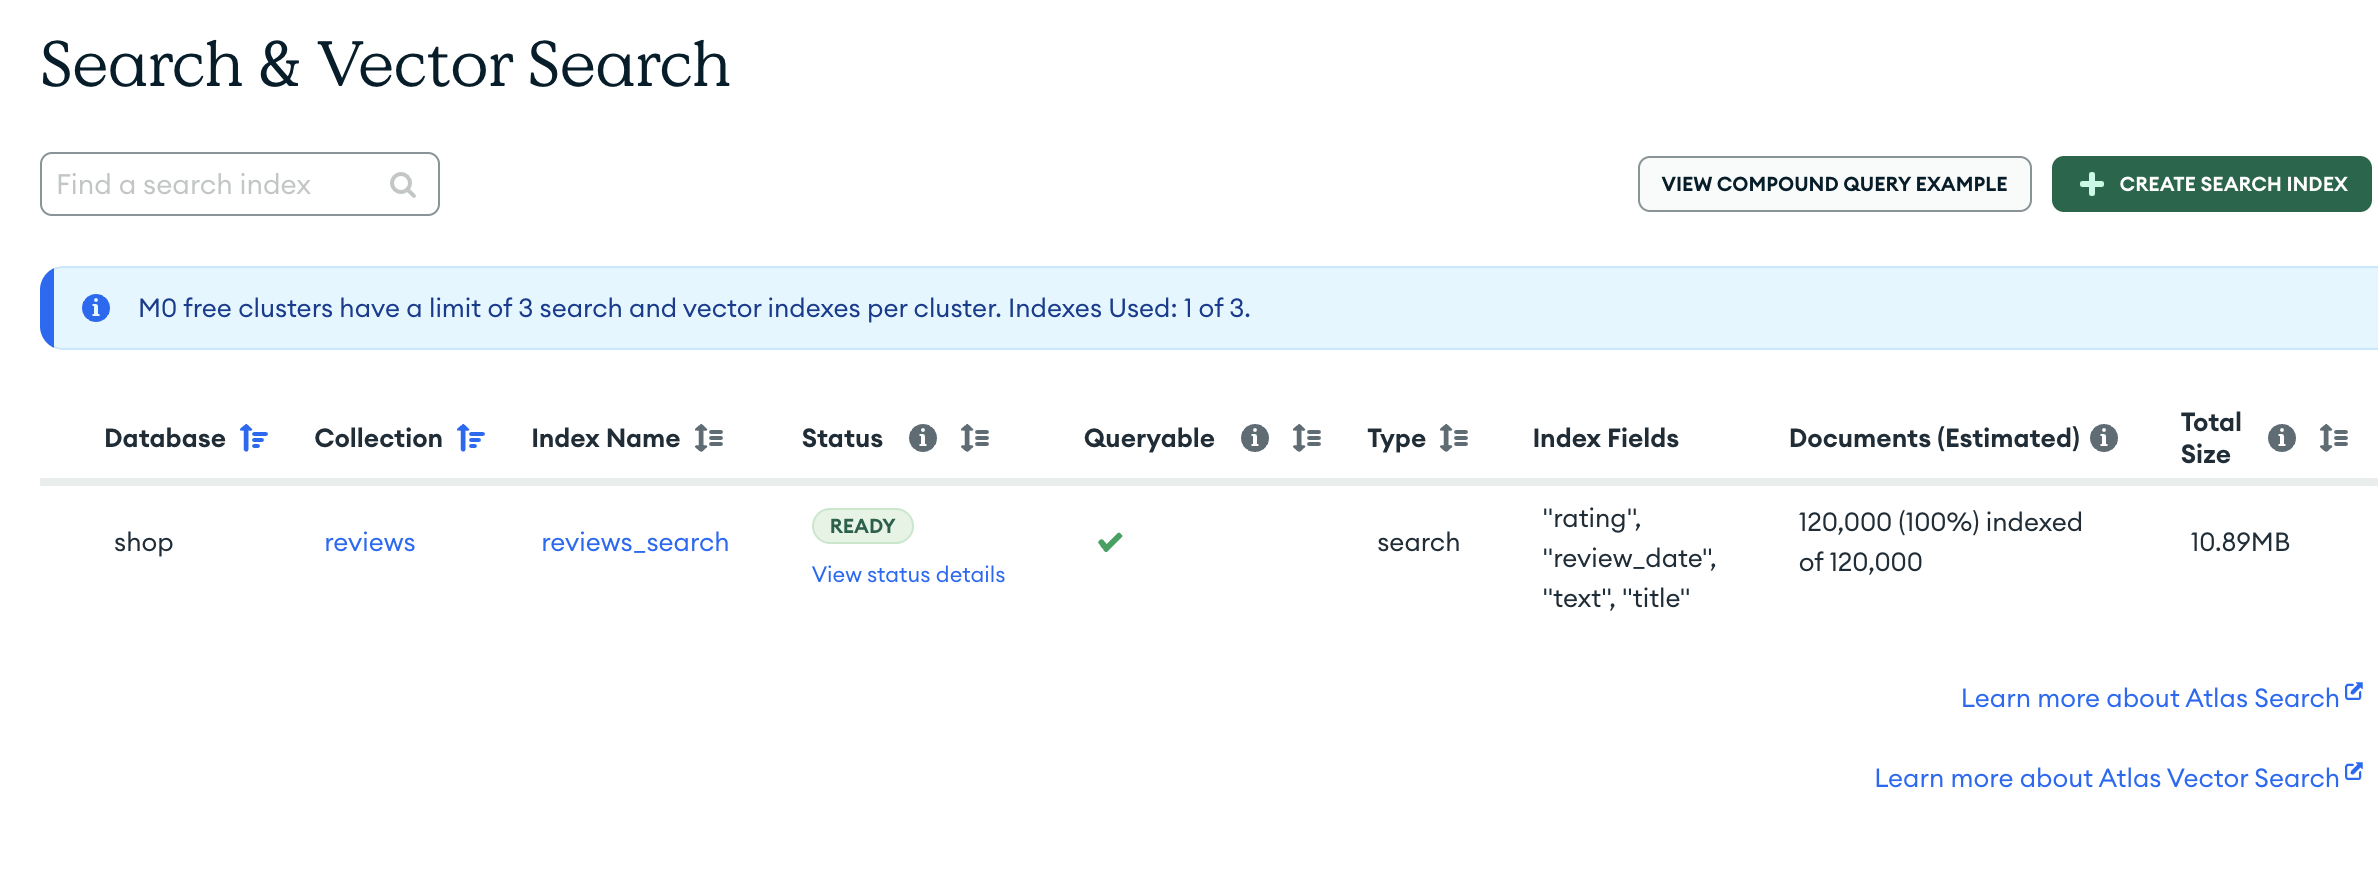

**2 orders validator**

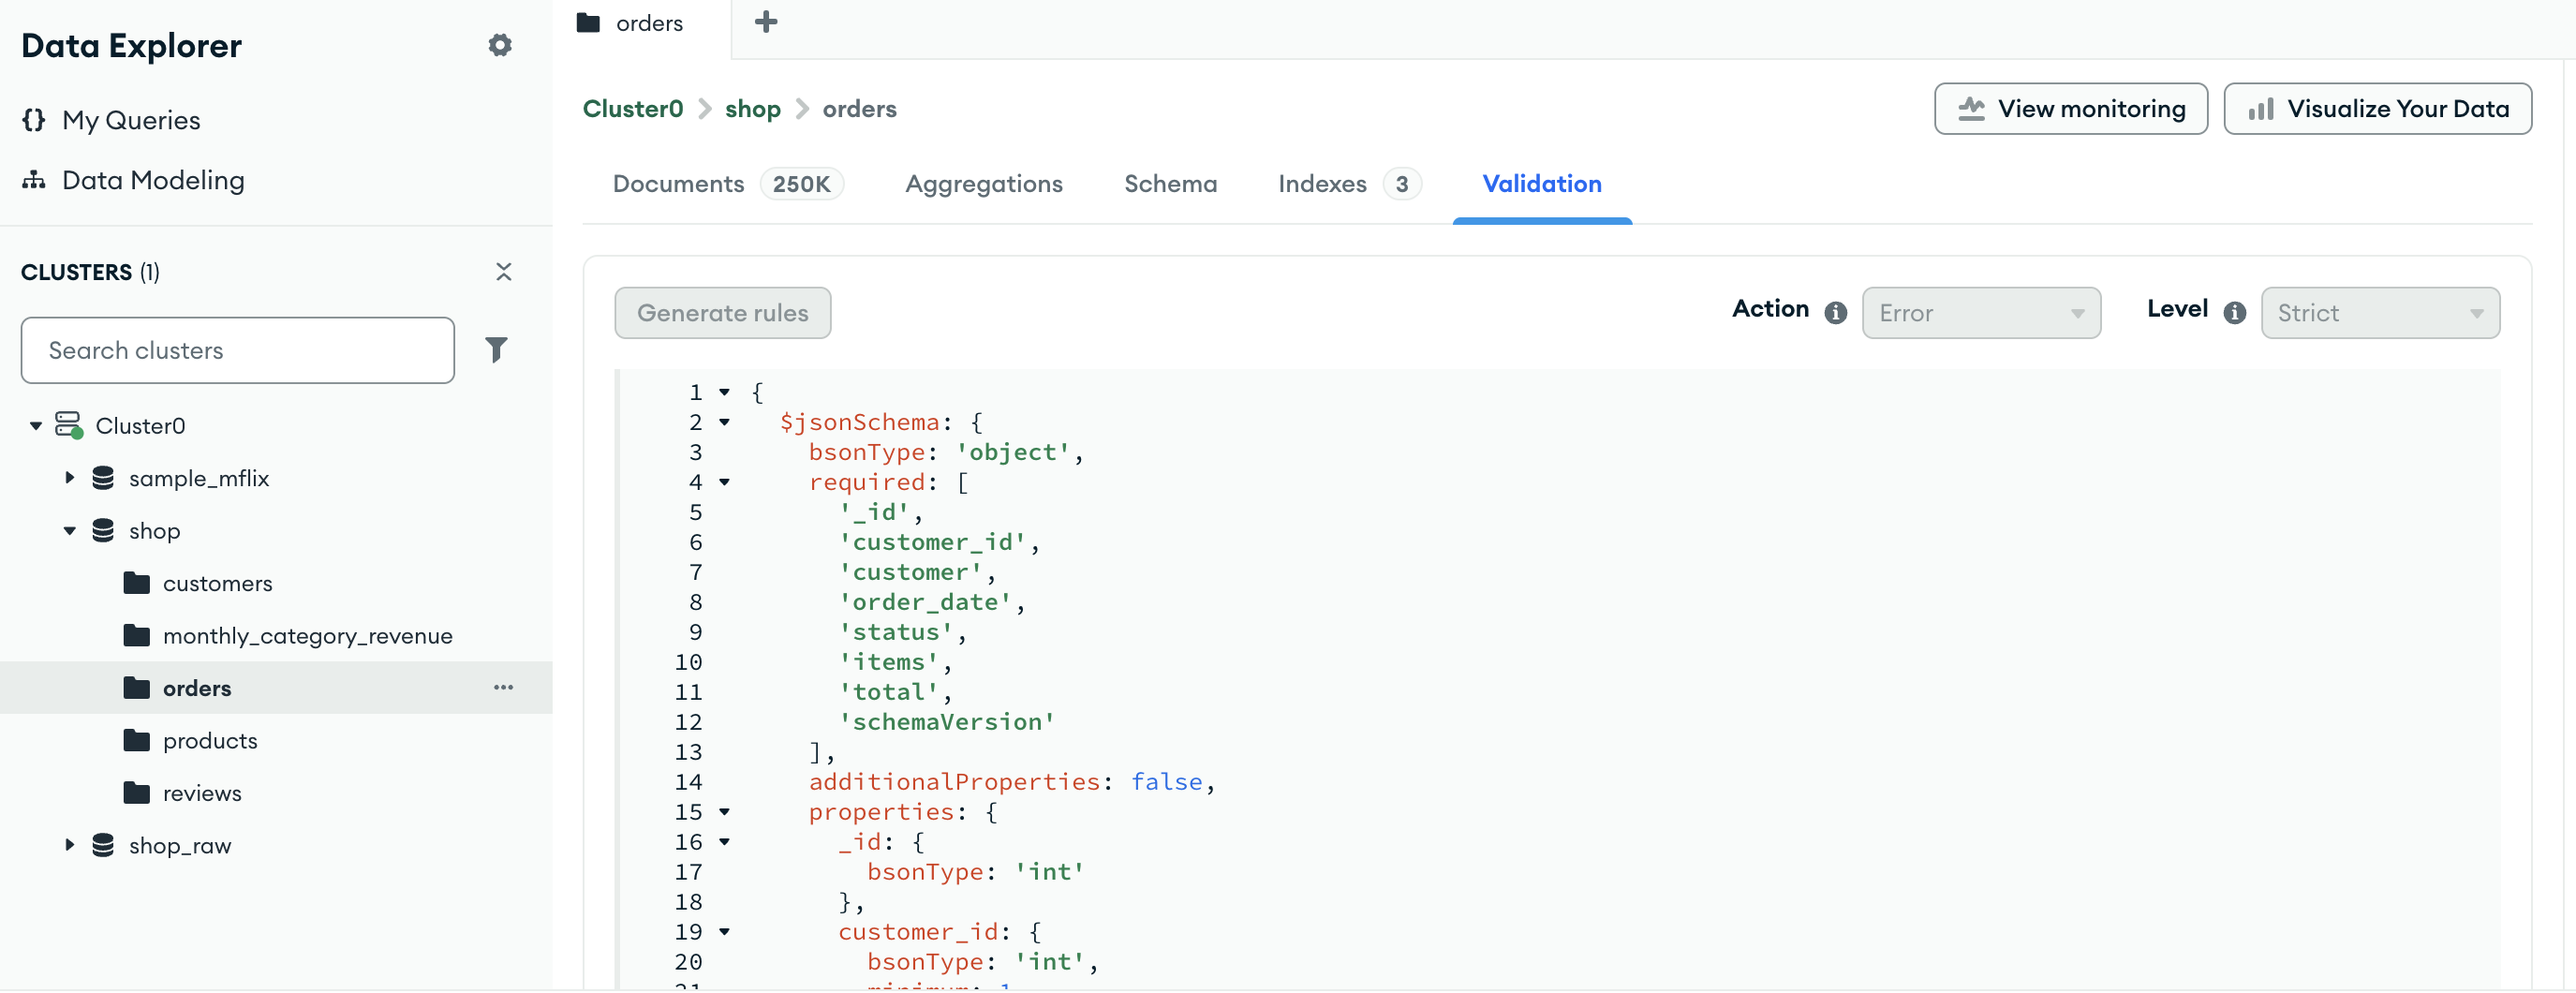

**3 database users**

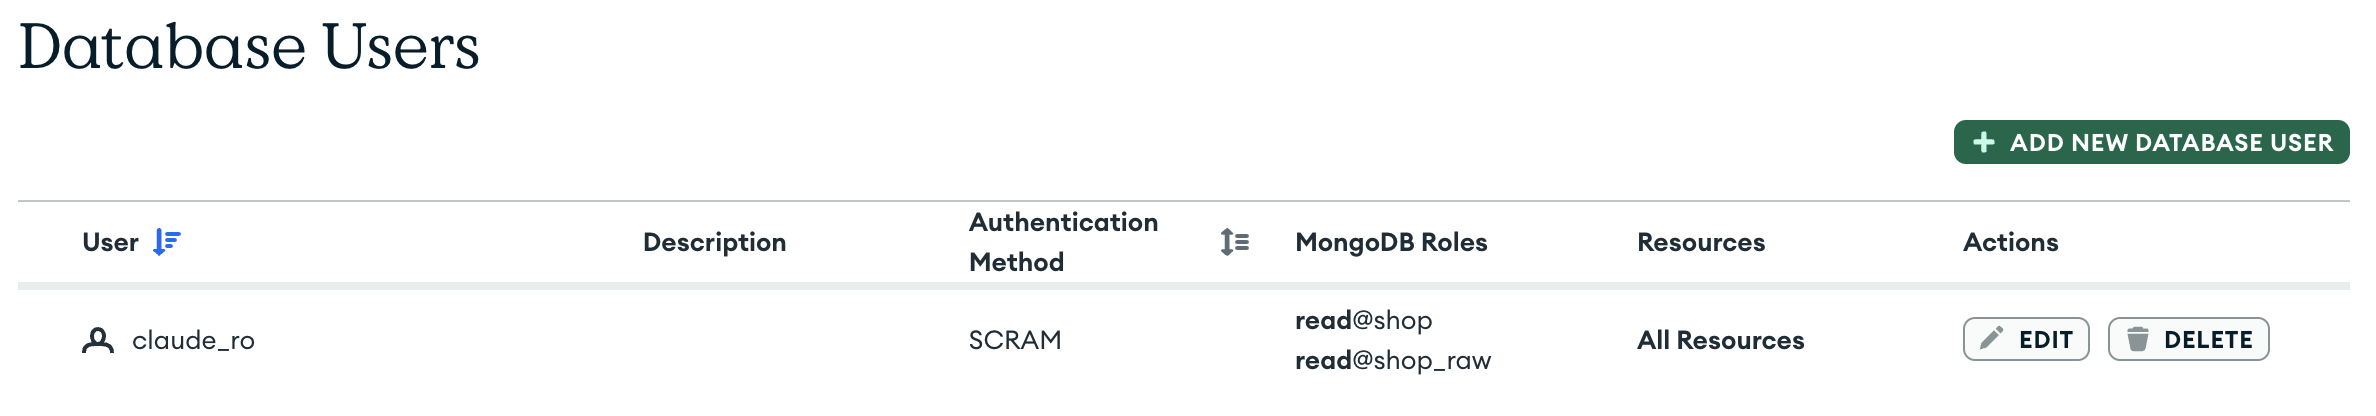

3 screenshot(s) embedded


In [30]:
shots = sorted(f for f in os.listdir("screenshots") if f.lower().endswith((".png", ".jpg", ".jpeg"))) if os.path.isdir("screenshots") else []
for f in shots:
    display(Markdown(f"**{os.path.splitext(f)[0].replace('_', ' ')}**")); display(Image(filename=os.path.join("screenshots", f), width=900))
print(f"{len(shots)} screenshot(s) embedded" if shots else "no screenshots/ folder yet")